# Arena Forage Visualization

Visualize the arena forage environment with treat spheres and Gaussian scent intensity rendered as viridis-colored floor tiles.

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

if sys.platform == "darwin":
    os.environ["MUJOCO_GL"] = "glfw"
else:
    os.environ["MUJOCO_GL"] = "egl"

import jax
import jax.numpy as jp
import mujoco
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

%matplotlib inline
%config InlineBackend.figure_format='retina'

## Configuration

Adjust these parameters to tune treat placement, scent spread, and visualization.

In [2]:
# Treat parameters
NUM_TREATS = 10
TREAT_SPHERE_RADIUS = 0.06
TREAT_HEIGHT = 0.03
MIN_SPAWN_RADIUS = 1.0
MAX_SPAWN_RADIUS = 2.0
SCENT_SIGMA = 0.2
SEED = 42

# Scent grid rendering
SCENT_GRID_EXTENT = 5.0  # half-size of the scent tile grid (meters), matches arena
SCENT_GRID_RESOLUTION = 100  # tiles per axis (40x40 = 1600 tiles)
SCENT_THRESHOLD = 0  # min scent to render a tile (skip near-zero)

# Toggle individual treats on/off to see scent update
COLLECTED_MASK = [False] * NUM_TREATS

## Sample Treat Positions

In [3]:
# Sample treat positions using jittered grid (stratified sampling)
# Divides the disk into angular sectors and radial bands, then samples
# one treat per sector with random jitter — prevents clustering while
# keeping positions random.
# Treats spawn in the annular region between MIN_SPAWN_RADIUS and MAX_SPAWN_RADIUS.

rng = jax.random.PRNGKey(SEED)
angle_rng, radius_rng = jax.random.split(rng)

# Angular: divide circle into NUM_TREATS equal sectors, jitter within each
sector_width = 2 * np.pi / NUM_TREATS
base_angles = np.linspace(0, 2 * np.pi, NUM_TREATS, endpoint=False)
angle_jitter = jax.random.uniform(
    angle_rng, (NUM_TREATS,), minval=0, maxval=sector_width
)
angles = base_angles + angle_jitter

# Radial: stratified bands from MIN_SPAWN_RADIUS to MAX_SPAWN_RADIUS
# Using sqrt for uniform-area sampling within each band
band_edges = np.linspace(MIN_SPAWN_RADIUS, MAX_SPAWN_RADIUS, NUM_TREATS + 1)
band_lo = band_edges[:-1]
band_hi = band_edges[1:]
# Shuffle band assignments so radius isn't correlated with angle
band_order = jax.random.permutation(jax.random.PRNGKey(SEED + 1), NUM_TREATS)
band_lo = band_lo[band_order]
band_hi = band_hi[band_order]
# Uniform-area sampling within each annular band: r = sqrt(uniform(lo^2, hi^2))
u = jax.random.uniform(radius_rng, (NUM_TREATS,))
radii = jp.sqrt(band_lo**2 + u * (band_hi**2 - band_lo**2))

treat_positions = np.array(
    jp.stack(
        [
            radii * jp.cos(angles),
            radii * jp.sin(angles),
            jp.full((NUM_TREATS,), TREAT_HEIGHT),
        ],
        axis=-1,
    )
)
collected = np.array(COLLECTED_MASK, dtype=bool)

print("Treat positions (jittered grid):")
for i, (pos, col) in enumerate(zip(treat_positions, collected)):
    status = "COLLECTED" if col else "active"
    print(f"  treat_{i}: ({pos[0]:+.3f}, {pos[1]:+.3f}, {pos[2]:.3f})  [{status}]")

Treat positions (jittered grid):
  treat_0: (+1.015, +0.351, 0.030)  [active]
  treat_1: (+1.071, +1.160, 0.030)  [active]
  treat_2: (-0.354, +1.374, 0.030)  [active]
  treat_3: (-1.317, +1.406, 0.030)  [active]
  treat_4: (-1.759, +0.431, 0.030)  [active]
  treat_5: (-1.221, -0.503, 0.030)  [active]
  treat_6: (-0.535, -0.999, 0.030)  [active]
  treat_7: (-0.220, -1.191, 0.030)  [active]
  treat_8: (+0.563, -1.650, 0.030)  [active]
  treat_9: (+1.627, -0.269, 0.030)  [active]


## Compute Scent Grid

In [4]:
# Build 2D scent intensity grid
grid_1d = np.linspace(-SCENT_GRID_EXTENT, SCENT_GRID_EXTENT, SCENT_GRID_RESOLUTION)
gx, gy = np.meshgrid(grid_1d, grid_1d)
scent_grid = np.zeros_like(gx)

for i in range(NUM_TREATS):
    if collected[i]:
        continue
    tx, ty = treat_positions[i, 0], treat_positions[i, 1]
    dist2 = (gx - tx) ** 2 + (gy - ty) ** 2
    scent_grid += np.exp(-dist2 / (2 * SCENT_SIGMA**2))

print(f"Scent grid shape: {scent_grid.shape}")
print(f"Scent range: [{scent_grid.min():.4f}, {scent_grid.max():.4f}]")
print(
    f"Tiles above threshold: {(scent_grid > SCENT_THRESHOLD).sum()} / {scent_grid.size}"
)

Scent grid shape: (100, 100)
Scent range: [0.0000, 1.2856]
Tiles above threshold: 10000 / 10000


## 2D Scent Heatmap (matplotlib)

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/arena_forage_scent_field.[pdf|svg|png]


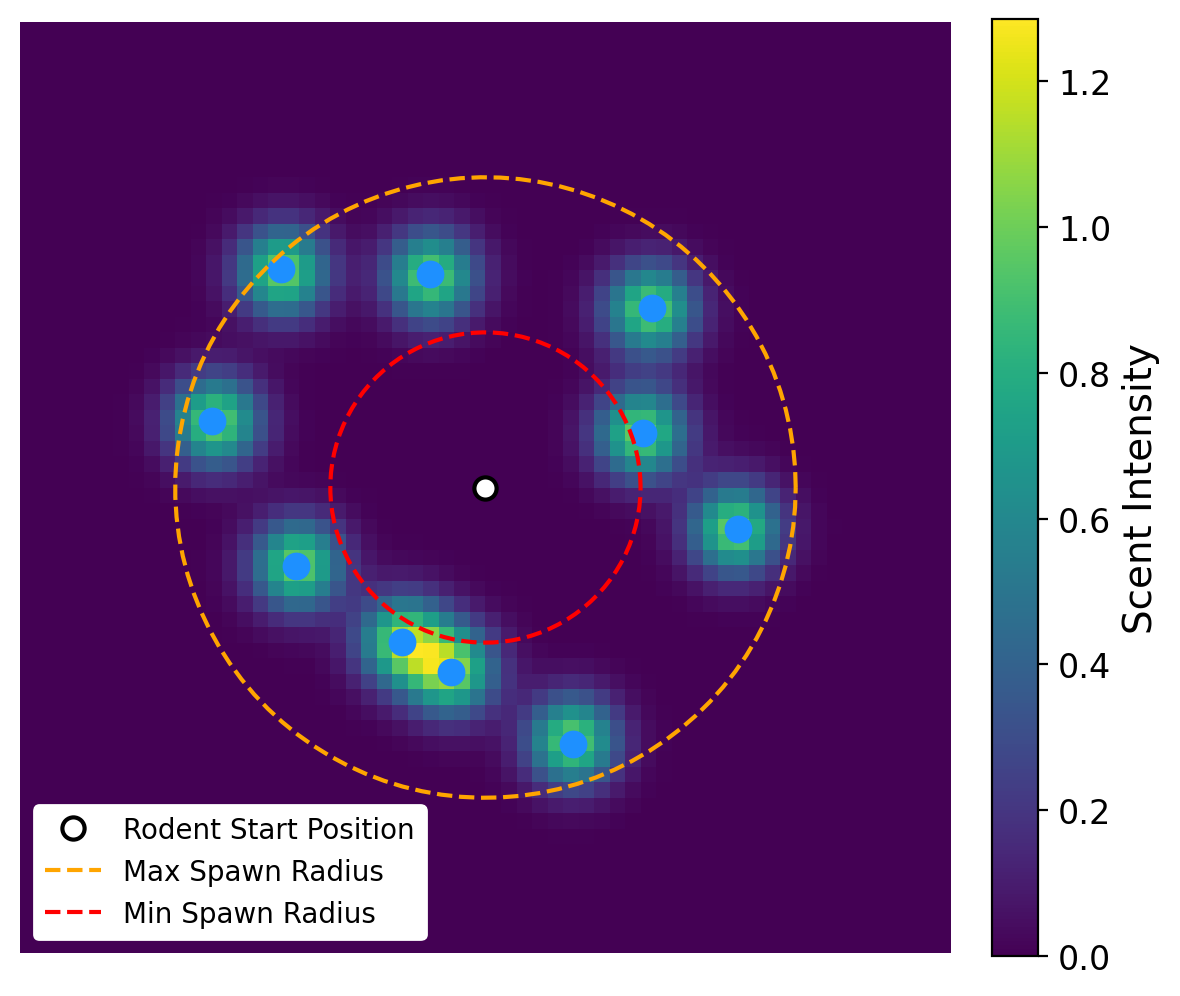

In [5]:
from pathlib import Path

extent = MAX_SPAWN_RADIUS * 1.5
vmax = max(float(scent_grid.max()), 1.0)

fig, ax = plt.subplots(figsize=(6, 6))

# Scent heatmap
im = ax.imshow(
    scent_grid,
    extent=[
        -SCENT_GRID_EXTENT,
        SCENT_GRID_EXTENT,
        -SCENT_GRID_EXTENT,
        SCENT_GRID_EXTENT,
    ],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=vmax,
    aspect="equal",
)

# Treat positions
for i in range(NUM_TREATS):
    color = "gray" if collected[i] else "dodgerblue"
    marker = "x" if collected[i] else "o"
    ax.plot(
        treat_positions[i, 0],
        treat_positions[i, 1],
        marker=marker,
        color=color,
        markersize=8,
        markeredgewidth=2,
        linestyle="None",
    )

# Rodent start position
ax.plot(
    0,
    0,
    "o",
    color="white",
    markersize=8,
    markeredgecolor="black",
    markeredgewidth=1.5,
    linestyle="None",
    label="Rodent Start Position",
    zorder=5,
)

# Spawn radius circles
theta = np.linspace(0, 2 * np.pi, 100)
ax.plot(
    MAX_SPAWN_RADIUS * np.cos(theta),
    MAX_SPAWN_RADIUS * np.sin(theta),
    color="orange",
    linestyle="--",
    alpha=1.0,
    linewidth=1.5,
    label="Max Spawn Radius",
)
ax.plot(
    MIN_SPAWN_RADIUS * np.cos(theta),
    MIN_SPAWN_RADIUS * np.sin(theta),
    "r--",
    alpha=1.0,
    linewidth=1.5,
    label="Min Spawn Radius",
)

ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.axis("off")

# Legend
ax.legend(
    fontsize=10,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="white",
    framealpha=1.0,
)

# Colorbar for scent field
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Scent Intensity", fontsize=14)
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()

# Save
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "arena_forage_scent_field"
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()

## Build MuJoCo Model with Scent Floor Tiles

Construct a MuJoCo scene from the arena XML, add treat spheres and viridis-colored floor tiles showing scent intensity.

In [6]:
from scamper.environment.rodent import consts

# Load arena spec
spec = mujoco.MjSpec.from_file(str(consts.ARENA_XML_PATH))

# Add treat spheres
for i in range(NUM_TREATS):
    if collected[i]:
        pos = [0, 0, -10]  # hidden
    else:
        pos = treat_positions[i].tolist()
    spec.worldbody.add_geom(
        name=f"treat_{i}",
        type=mujoco.mjtGeom.mjGEOM_SPHERE,
        pos=pos,
        size=[TREAT_SPHERE_RADIUS],
        rgba=[0.2, 0.4, 1.0, 0.8],
        contype=0,
        conaffinity=0,
    )

# Add scent floor tiles
tile_size = SCENT_GRID_EXTENT / SCENT_GRID_RESOLUTION  # half-size of each tile
tile_count = 0
for row in range(SCENT_GRID_RESOLUTION):
    for col in range(SCENT_GRID_RESOLUTION):
        intensity = scent_grid[row, col]
        if intensity < SCENT_THRESHOLD:
            continue
        clamped = min(intensity, 1.0)
        rgba = list(cm.viridis(clamped))
        rgba[3] = clamped * 0.6  # alpha proportional to intensity
        cx = grid_1d[col]
        cy = grid_1d[row]
        spec.worldbody.add_geom(
            name=f"scent_{tile_count}",
            type=mujoco.mjtGeom.mjGEOM_BOX,
            pos=[cx, cy, 0],
            size=[tile_size, tile_size, 0.0001],
            rgba=rgba,
            contype=0,
            conaffinity=0,
        )
        tile_count += 1

# Add overhead light
spec.worldbody.add_light(pos=[0, 0, 10], dir=[0, 0, -1])

# Compile
model = spec.compile()
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

print(f"Added {tile_count} scent tiles and {NUM_TREATS} treat spheres")
print(f"Total geoms in model: {model.ngeom}")

Added 10000 scent tiles and 10 treat spheres
Total geoms in model: 10011


## Render 3D Views

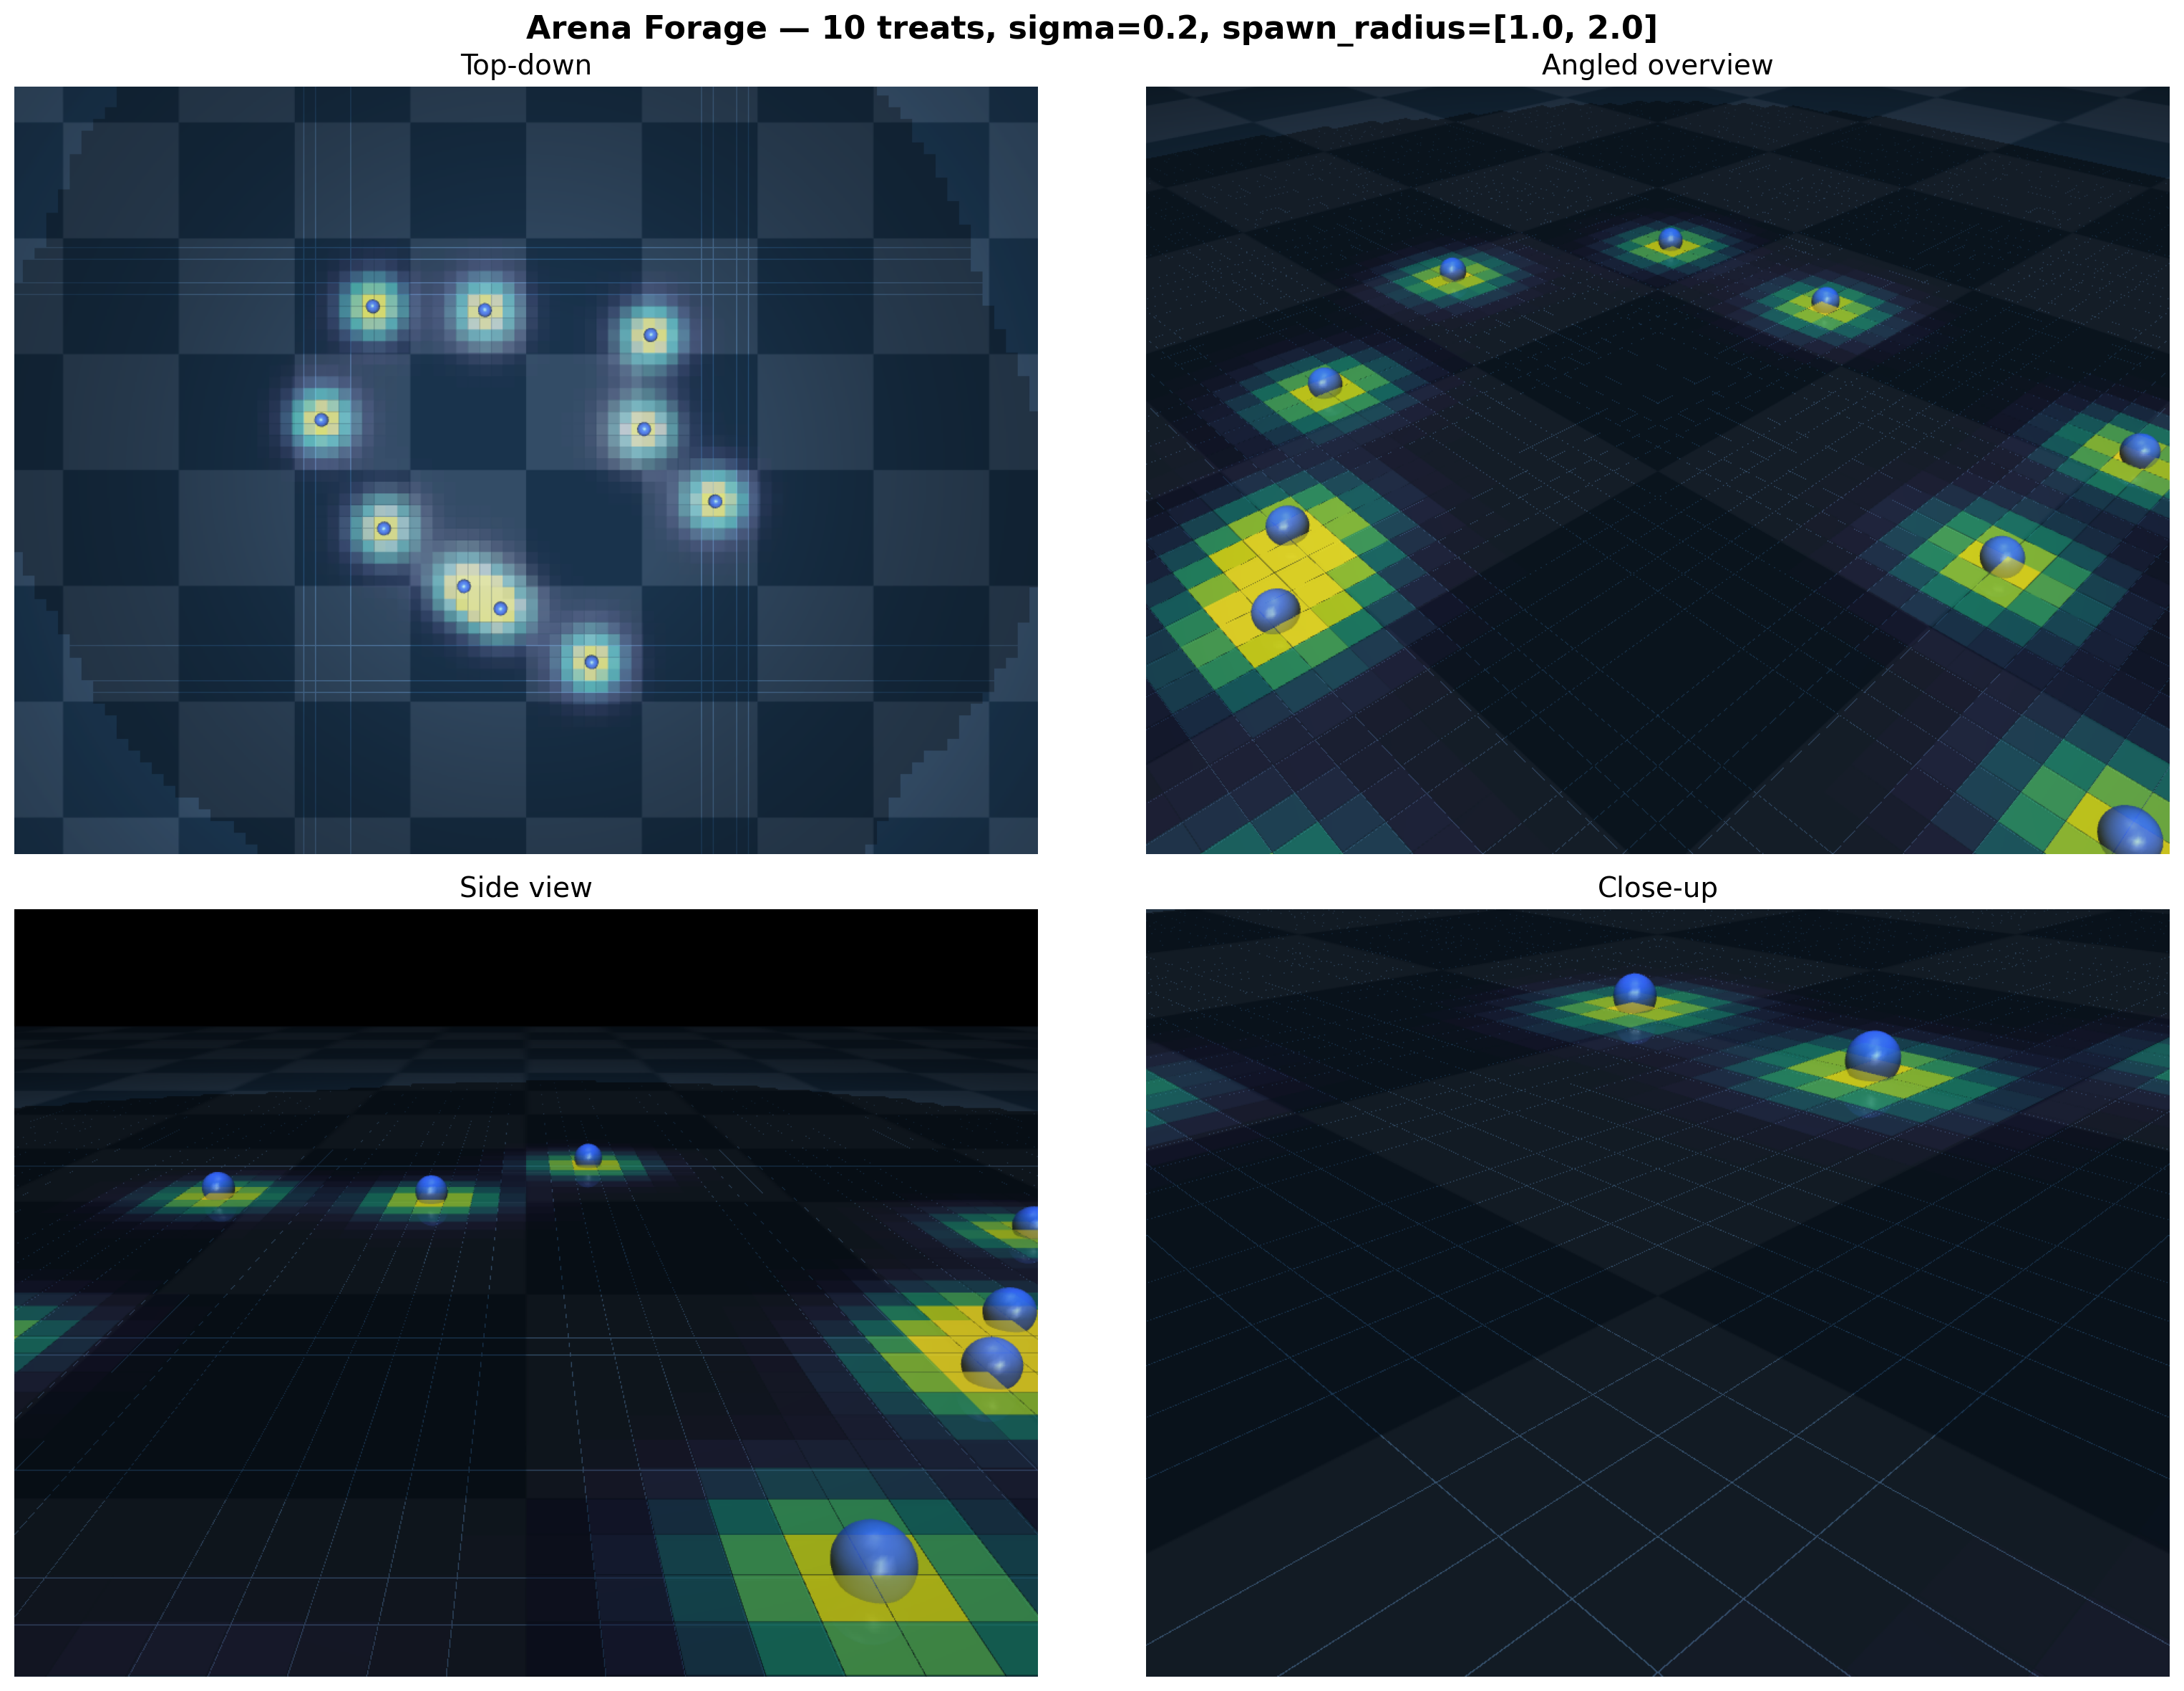

In [7]:
renderer = mujoco.Renderer(model, height=720, width=960)

cameras = {
    "Top-down": dict(azimuth=90, elevation=-90, distance=8.0, lookat=[0, 0, 0]),
    "Angled overview": dict(azimuth=135, elevation=-35, distance=3.0, lookat=[0, 0, 0]),
    "Side view": dict(azimuth=0, elevation=-20, distance=2.5, lookat=[0, 0, 0]),
    "Close-up": dict(azimuth=45, elevation=-30, distance=1.2, lookat=[0, 0, 0]),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (name, cam_kwargs) in zip(axes.flat, cameras.items()):
    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_FREE
    cam.fixedcamid = -1
    cam.trackbodyid = -1
    cam.lookat[:] = cam_kwargs["lookat"]
    cam.distance = cam_kwargs["distance"]
    cam.azimuth = cam_kwargs["azimuth"]
    cam.elevation = cam_kwargs["elevation"]
    renderer.update_scene(data, camera=cam)
    frame = renderer.render()
    ax.imshow(frame)
    ax.set_title(name, fontsize=14)
    ax.axis("off")

plt.suptitle(
    f"Arena Forage — {NUM_TREATS} treats, sigma={SCENT_SIGMA}, spawn_radius=[{MIN_SPAWN_RADIUS}, {MAX_SPAWN_RADIUS}]",
    fontsize=16,
    fontweight="bold",
)
plt.tight_layout()
plt.show()
renderer.close()

## Environment Smoke Test

Verify that the `ArenaForage` environment compiles, resets, and steps correctly under `jax.jit`.

In [ ]:
from scamper.environment.rodent.arena_forage import ArenaForage, default_config

cfg = default_config()
cfg.num_treats = NUM_TREATS
cfg.treat_sphere_radius = TREAT_SPHERE_RADIUS
cfg.treat_height = TREAT_HEIGHT
cfg.min_spawn_radius = MIN_SPAWN_RADIUS
cfg.spawn_radius = MAX_SPAWN_RADIUS
cfg.scent_sigma = SCENT_SIGMA

env = ArenaForage(config=cfg)
print(f"Action size: {env.action_size}")
print(f"Observation size: {env.observation_size}")

In [ ]:
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

state = jit_reset(jax.random.PRNGKey(0))

print(f"Obs keys: {list(state.obs.keys())}")
print(f"Obs shapes: {jax.tree.map(lambda x: x.shape, state.obs)}")
print(f"Treat positions:\n{state.info['treat_positions']}")
print(f"Treat collected: {state.info['treat_collected']}")
print(f"Reward: {state.reward}")
print(f"Done: {state.done}")

In [ ]:
# Run a few steps with zero action
state_after = state
for _ in range(10):
    action = jp.zeros(env.action_size)
    state_after = jit_step(state_after, action)

print(f"After 10 steps:")
print(f"  Reward: {state_after.reward}")
print(f"  Done: {state_after.done}")
print(f"  Treats collected: {state_after.info['treat_collected']}")
print(f"  task_obs shape: {state_after.obs['task_obs'].shape}")

## Render Environment with `env.render()`

In [ ]:
# Collect a short rollout for rendering
rollout_states = [state]
s = state
for _ in range(50):
    action = jp.zeros(env.action_size)
    s = jit_step(s, action)
    rollout_states.append(s)

# Debug: verify treat geom IDs are valid
mj_model = env.mj_model
for i in range(NUM_TREATS):
    gid = mujoco.mj_name2id(mj_model, mujoco.mjtObj.mjOBJ_GEOM, f"treat_{i}")
    print(f"treat_{i} geom_id={gid}, model geom_pos={mj_model.geom_pos[gid]}")

# Render with explicit camera aimed at the rodent area
cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_FREE
cam.lookat[:] = [0, 0, 0.05]
cam.distance = 1.5
cam.azimuth = 135
cam.elevation = -30

frames = env.render(rollout_states, height=480, width=640, camera=cam)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(frames[0])
axes[0].set_title("Frame 0 (after reset)", fontsize=13)
axes[0].axis("off")
axes[1].imshow(frames[-1])
axes[1].set_title(f"Frame {len(frames)-1}", fontsize=13)
axes[1].axis("off")
plt.suptitle(
    "env.render() — treat spheres at sampled positions", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

## Parameter Comparison

Render side-by-side views with different scent sigma values.

In [ ]:
sigmas = [0.1, 0.3, 0.5, 1.0]

fig, axes = plt.subplots(1, len(sigmas), figsize=(5 * len(sigmas), 5))

for ax, sigma in zip(axes, sigmas):
    grid = np.zeros_like(gx)
    for i in range(NUM_TREATS):
        if collected[i]:
            continue
        tx, ty = treat_positions[i, 0], treat_positions[i, 1]
        dist2 = (gx - tx) ** 2 + (gy - ty) ** 2
        grid += np.exp(-dist2 / (2 * sigma**2))

    ax.imshow(
        grid,
        extent=[
            -SCENT_GRID_EXTENT,
            SCENT_GRID_EXTENT,
            -SCENT_GRID_EXTENT,
            SCENT_GRID_EXTENT,
        ],
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=max(grid.max(), 1.0),
    )
    for i in range(NUM_TREATS):
        if not collected[i]:
            ax.plot(
                treat_positions[i, 0],
                treat_positions[i, 1],
                "o",
                color="dodgerblue",
                markersize=6,
            )
    ax.set_title(f"sigma = {sigma}", fontsize=13)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")

axes[0].set_ylabel("y (m)")
plt.suptitle("Scent Field — Varying Sigma", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## Collection Effect

Show scent field before and after collecting treats 0 and 1.

In [ ]:
masks = [
    ([False] * NUM_TREATS, "All active"),
    ([True, True, False, False, False], "Treats 0,1 collected"),
    ([True, True, True, True, False], "Only treat 4 left"),
]

fig, axes = plt.subplots(1, len(masks), figsize=(6 * len(masks), 5))

for ax, (mask, title) in zip(axes, masks):
    col_arr = np.array(mask, dtype=bool)
    grid = np.zeros_like(gx)
    for i in range(NUM_TREATS):
        if col_arr[i]:
            continue
        tx, ty = treat_positions[i, 0], treat_positions[i, 1]
        dist2 = (gx - tx) ** 2 + (gy - ty) ** 2
        grid += np.exp(-dist2 / (2 * SCENT_SIGMA**2))

    ax.imshow(
        grid,
        extent=[
            -SCENT_GRID_EXTENT,
            SCENT_GRID_EXTENT,
            -SCENT_GRID_EXTENT,
            SCENT_GRID_EXTENT,
        ],
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=max(scent_grid.max(), 1.0),  # same scale
    )
    for i in range(NUM_TREATS):
        color = "gray" if col_arr[i] else "dodgerblue"
        marker = "x" if col_arr[i] else "o"
        ax.plot(
            treat_positions[i, 0],
            treat_positions[i, 1],
            marker=marker,
            color=color,
            markersize=8,
        )
    ax.set_title(title, fontsize=13)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")

axes[0].set_ylabel("y (m)")
plt.suptitle(
    f"Scent Field — Collection Effect (sigma={SCENT_SIGMA})",
    fontsize=15,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

## Scent Heatmap Animation

Animated 2D scent heatmap with rodent trajectory (red dot + trail), treat positions, and spawn radius. Uses a random-action rollout to preview the visualization logged to wandb during training.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Collect a rollout with random actions
rng = jax.random.PRNGKey(42)
reset_rng, act_rng = jax.random.split(rng)
rollout_states = [jit_reset(reset_rng)]
s = rollout_states[0]
for _ in range(500):
    act_rng, key = jax.random.split(act_rng)
    action = jax.random.normal(key, (env.action_size,)) * 0.3
    s = jit_step(s, action)
    rollout_states.append(s)

# Extract data from rollout
num_treats = cfg.num_treats
sigma = cfg.scent_sigma
extent = cfg.spawn_radius * 1.5
grid_resolution = 60

grid_1d = np.linspace(-extent, extent, grid_resolution)
gx, gy = np.meshgrid(grid_1d, grid_1d)

treat_pos = np.array(rollout_states[0].info["treat_positions"])
scent_per_treat = np.zeros((num_treats, grid_resolution, grid_resolution))
for t in range(num_treats):
    dist2 = (gx - treat_pos[t, 0]) ** 2 + (gy - treat_pos[t, 1]) ** 2
    scent_per_treat[t] = np.exp(-dist2 / (2 * sigma**2))

rodent_xy = np.array([np.array(s.data.qpos[:2]) for s in rollout_states])
vmax = max(float(scent_per_treat.sum(axis=0).max()), 1.0)

# Build animation
fig, ax = plt.subplots(figsize=(6, 6))

# Static elements — spawn radius circles
theta_circle = np.linspace(0, 2 * np.pi, 100)
max_spawn_x = MAX_SPAWN_RADIUS * np.cos(theta_circle)
max_spawn_y = MAX_SPAWN_RADIUS * np.sin(theta_circle)
min_spawn_x = MIN_SPAWN_RADIUS * np.cos(theta_circle)
min_spawn_y = MIN_SPAWN_RADIUS * np.sin(theta_circle)

# Initialize plot elements
im = ax.imshow(
    np.zeros((grid_resolution, grid_resolution)),
    extent=[-extent, extent, -extent, extent],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=vmax,
    aspect="equal",
)
treat_plots = []
for t in range(num_treats):
    (p,) = ax.plot([], [], "o", color="dodgerblue", markersize=7, markeredgewidth=2)
    treat_plots.append(p)
(max_spawn_line,) = ax.plot(
    max_spawn_x, max_spawn_y, "w--", alpha=0.4, linewidth=0.8, label="max spawn radius"
)
(min_spawn_line,) = ax.plot(
    min_spawn_x, min_spawn_y, "r--", alpha=0.4, linewidth=0.8, label="min spawn radius"
)
(trail_line,) = ax.plot([], [], "r-", alpha=0.4, linewidth=0.8)
(pos_dot,) = ax.plot([], [], "ro", markersize=6)
title = ax.set_title("")
ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(loc="upper right")
fig.tight_layout()


def update(i):
    state = rollout_states[i]
    collected = np.array(state.info["treat_collected"])
    active = ~collected

    # Update scent field
    if active.any():
        scent_grid = np.sum(scent_per_treat[active], axis=0)
    else:
        scent_grid = np.zeros_like(gx)
    im.set_data(scent_grid)

    # Update treat markers
    for t in range(num_treats):
        if collected[t]:
            treat_plots[t].set_data([treat_pos[t, 0]], [treat_pos[t, 1]])
            treat_plots[t].set_marker("x")
            treat_plots[t].set_color("gray")
        else:
            treat_plots[t].set_data([treat_pos[t, 0]], [treat_pos[t, 1]])
            treat_plots[t].set_marker("o")
            treat_plots[t].set_color("dodgerblue")

    # Update rodent trail and position
    trail = rodent_xy[: i + 1]
    trail_line.set_data(trail[:, 0], trail[:, 1])
    pos_dot.set_data([rodent_xy[i, 0]], [rodent_xy[i, 1]])
    title.set_text(f"Scent Field — frame {i}")

    return [im, trail_line, pos_dot, title] + treat_plots


anim = FuncAnimation(fig, update, frames=len(rollout_states), interval=20, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())